# MachineEar — Exploration audio et extraction des caractéristiques
Exécuter les cellules dans l’ordre depuis VS Code. Le dossier audio attendu est `data/0_dB_fan/id_00`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import librosa
import librosa.display
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
AUDIO_DIR = ROOT / "data" / "0_dB_fan" / "id_00"
OUTPUT_DIR = ROOT / "data" / "processed"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
assert AUDIO_DIR.is_dir(), f"Dossier introuvable : {AUDIO_DIR}"
files = sorted(AUDIO_DIR.rglob("*.wav"))
print(f"{len(files)} fichiers WAV trouvés dans {AUDIO_DIR}")
assert files, "Aucun WAV trouvé"

Matplotlib is building the font cache; this may take a moment.


1418 fichiers WAV trouvés dans C:\Users\0503506P\Downloads\MachineEar_VSCode\MachineEar\data\0_dB_fan\id_00


c:\Users\0503506P\Downloads\MachineEar_VSCode\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Aperçu de trois spectrogrammes
On essaie de sélectionner des fichiers normaux et anormaux lorsque ces dossiers existent.

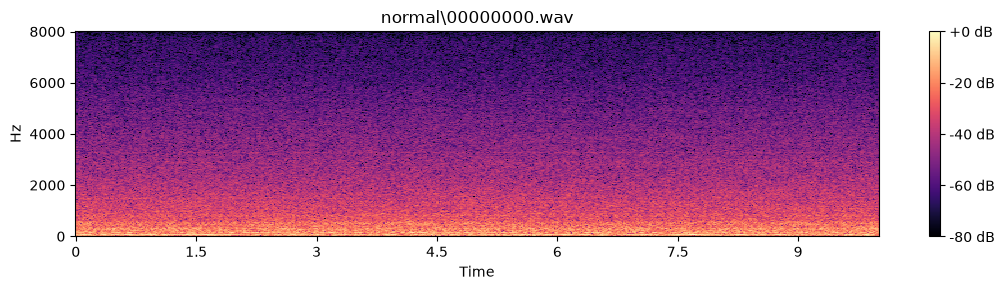

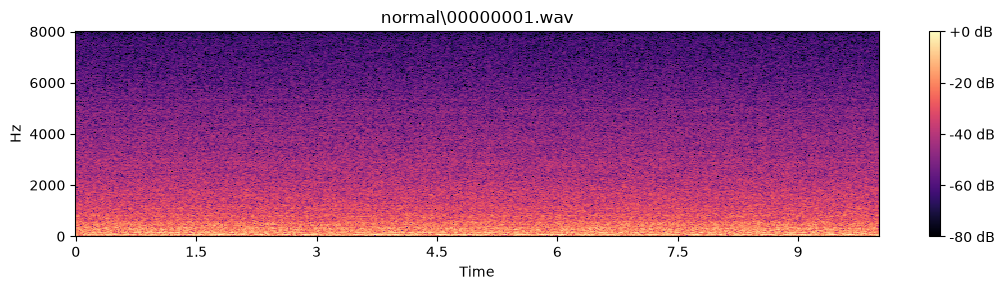

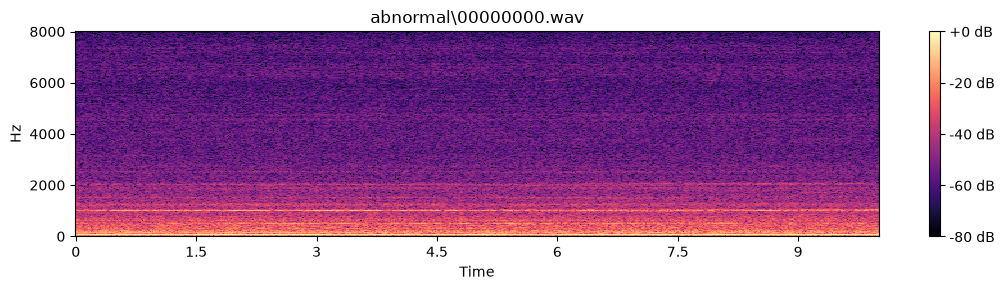

In [2]:
normal = [f for f in files if "normal" in f.parts and "abnormal" not in f.parts]
abnormal = [f for f in files if "abnormal" in f.parts]
examples = (normal[:2] + abnormal[:1]) if normal and abnormal else files[:3]
for file in examples:
    y, sr = librosa.load(file, sr=16000, mono=True)
    S = librosa.amplitude_to_db(abs(librosa.stft(y, n_fft=1024, hop_length=256)), ref=np.max)
    plt.figure(figsize=(11, 3))
    librosa.display.specshow(S, sr=sr, hop_length=256, x_axis="time", y_axis="linear", cmap="magma")
    plt.colorbar(format="%+2.0f dB")
    plt.title(str(file.relative_to(AUDIO_DIR)))
    plt.tight_layout()
    plt.show()

## Extraction des caractéristiques de tous les fichiers
Les MFCC et des statistiques spectrales forment une représentation compacte, pratique pour un premier modèle. On conserve le chemin et le label pour la suite.

In [3]:
def extract_features(file):
    y, sr = librosa.load(file, sr=16000, mono=True)
    if y.size == 0:
        raise ValueError("Audio vide")
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=20)
    features = {"file_path": str(file.relative_to(ROOT)), "duration_sec": len(y) / sr}
    for i, values in enumerate(mfcc, start=1):
        features[f"mfcc_{i:02d}_mean"] = float(np.mean(values))
        features[f"mfcc_{i:02d}_std"] = float(np.std(values))
    for name, arr in {
        "rms": librosa.feature.rms(y=y),
        "zcr": librosa.feature.zero_crossing_rate(y),
        "centroid": librosa.feature.spectral_centroid(y=y, sr=sr),
        "bandwidth": librosa.feature.spectral_bandwidth(y=y, sr=sr),
        "rolloff": librosa.feature.spectral_rolloff(y=y, sr=sr),
        "flatness": librosa.feature.spectral_flatness(y=y),
    }.items():
        features[f"{name}_mean"] = float(np.mean(arr))
        features[f"{name}_std"] = float(np.std(arr))
    parts = set(file.relative_to(AUDIO_DIR).parts)
    features["label"] = 1 if "abnormal" in parts else (0 if "normal" in parts else np.nan)
    return features

rows, errors = [], []
for file in tqdm(files, desc="Extraction audio"):
    try:
        rows.append(extract_features(file))
    except Exception as exc:
        errors.append({"file_path": str(file), "error": str(exc)})

df = pd.DataFrame(rows)
output = OUTPUT_DIR / "fan_id00_features.csv"
df.to_csv(output, index=False)
print(f"Fichier enregistré : {output} — {len(df)} lignes, {len(df.columns)} colonnes")
print(f"Erreurs : {len(errors)}")
display(df.head())
if errors:
    display(pd.DataFrame(errors).head())

Extraction audio: 100%|██████████| 1418/1418 [04:05<00:00,  5.77it/s]

Fichier enregistré : C:\Users\0503506P\Downloads\MachineEar_VSCode\MachineEar\data\processed\fan_id00_features.csv — 1418 lignes, 55 colonnes
Erreurs : 0


,file_path,duration_sec,mfcc_01_mean,mfcc_01_std,mfcc_02_mean,mfcc_02_std,mfcc_03_mean,mfcc_03_std,mfcc_04_mean,mfcc_04_std,...,zcr_std,centroid_mean,centroid_std,bandwidth_mean,bandwidth_std,rolloff_mean,rolloff_std,flatness_mean,flatness_std,label
0,data\0_dB_fan\id_00\abnormal\00000000.wav,10.0,-396.144806,3.402323,135.755417,2.970131,20.228804,3.011735,8.463317,2.858978,...,0.008237,977.723760,46.715186,1544.250499,40.589913,1750.299521,138.440346,0.003269,0.000824,1
1,data\0_dB_fan\id_00\abnormal\00000001.wav,10.0,-384.965607,4.134365,130.965836,3.116457,18.180664,2.755145,8.505290,2.902241,...,0.006617,1025.542845,43.763270,1583.041529,37.913310,1906.200080,144.761601,0.003485,0.000739,1
2,data\0_dB_fan\id_00\abnormal\00000002.wav,10.0,-391.158020,3.553493,125.811378,3.026743,27.886906,2.784920,14.952944,2.813266,...,0.006400,1023.551259,46.427222,1646.105570,44.674238,1994.608626,202.882425,0.003672,0.000877,1
3,data\0_dB_fan\id_00\abnormal\00000003.wav,10.0,-385.222290,4.044104,131.047226,3.088454,17.204878,3.255453,8.544799,3.055152,...,0.006056,1019.219748,41.424439,1570.191530,40.250307,1896.615415,144.310978,0.003400,0.000779,1
4,data\0_dB_fan\id_00\abnormal\00000004.wav,10.0,-389.398376,3.277032,146.362717,3.078448,-3.363282,2.994202,35.268394,2.809728,...,0.005433,864.240526,48.016516,1276.630418,34.411200,1784.195288,115.346389,0.002431,0.000887,1


**Important :** ce CSV est une première représentation statistique de chaque audio, pas une conversion exhaustive de chaque échantillon du signal. Pour un modèle CNN sur spectrogrammes, nous préparerons une autre représentation à l’étape d’entraînement. Pour éviter les fuites de données, les découpages train/test seront définis avant toute normalisation des variables.

In [4]:
import pandas as pd
import numpy as np

# Remplace df par le nom de ton DataFrame si nécessaire
print("Dimensions :", df.shape)

print("\nRépartition des classes :")
print(df["label"].value_counts())

print("\nValeurs manquantes :")
print(df.isnull().sum().sum())

print("\nDoublons :")
print(df["file_path"].duplicated().sum())

print("\nDurées :")
print(df["duration_sec"].describe())

print("\nNombre de colonnes numériques :")
print(df.select_dtypes(include=np.number).shape[1])

Dimensions : (1418, 55)

Répartition des classes :
label
0    1011
1     407
Name: count, dtype: int64

Valeurs manquantes :
0

Doublons :
0

Durées :
count    1418.0
mean       10.0
std         0.0
min        10.0
25%        10.0
50%        10.0
75%        10.0
max        10.0
Name: duration_sec, dtype: float64

Nombre de colonnes numériques :
54
